In [156]:
#data cleaning
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
df = pd.read_csv("/content/studentInfo.csv")
df.shape

(32593, 12)

In [157]:
print("total missing values:", df.isna().sum().sum())
print("duplicates:",df.duplicated().sum())
df.describe
print("amount of modules",np.count_nonzero(df["code_module"].unique()))
print(df["imd_band"].unique())
#for imd band repeats 50-60

total missing values: 0
duplicates: 0
amount of modules 7
['90-100%' '20-30%' '30-40%' '50-60%' '80-90%' '70-80%' '?' '60-70%'
 '40-50%' '10-20' '0-10%']


In [158]:
imd_map = {"0-10%": "0-10%","10-20": "10-20%","10-20%":"10-20%","20-30%": "20-30%","30-40%": "30-40%","40-50%": "40-50%",
           "50-60": "50-60%","50-60%" : "50-60%","60-70%":"60-70%","70-80%":"70-80%","80-90%":"80-90%","90-100%":"90-100%","?":"?"}

df["imd_band"] = (
    df["imd_band"].str.strip().str.lower().map(imd_map))
print(df["imd_band"].unique())

['90-100%' '20-30%' '30-40%' '50-60%' '80-90%' '70-80%' '?' '60-70%'
 '40-50%' '10-20%' '0-10%']


In [159]:
(df["imd_band"] == "?").sum()
imd_labels = df["imd_band"].unique()
print(imd_labels)

['90-100%' '20-30%' '30-40%' '50-60%' '80-90%' '70-80%' '?' '60-70%'
 '40-50%' '10-20%' '0-10%']


In [160]:
#add chloe's code which deals with this

In [161]:
#ordinal encoding


In [162]:
edorder = ["No Formal quals","Lower Than A Level","A Level or Equivalent","HE Qualification","Post Graduate Qualification"]
education_encoder = OrdinalEncoder(categories=[edorder])
imdorder = ['?','0-10%','10-20%','20-30%','30-40%','40-50%','50-60%','60-70%','70-80%','80-90%','90-100%']
imd_encoder = OrdinalEncoder(categories=[imdorder])
ageorder = ['55<=', '35-55' ,'0-35']
age_encoder = OrdinalEncoder(categories=[ageorder])



df["highest_education"] = education_encoder.fit_transform(df[["highest_education"]])
df["imd_band"] = imd_encoder.fit_transform(df[["imd_band"]])
df["age_band"] = age_encoder.fit_transform(df[["age_band"]])
df

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,3.0,10.0,0.0,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,3.0,3.0,1.0,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,2.0,4.0,1.0,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,2.0,6.0,1.0,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,1.0,6.0,2.0,0,60,N,Pass
...,...,...,...,...,...,...,...,...,...,...,...,...
32588,GGG,2014J,2640965,F,Wales,1.0,2.0,2.0,0,30,N,Fail
32589,GGG,2014J,2645731,F,East Anglian Region,1.0,5.0,1.0,0,30,N,Distinction
32590,GGG,2014J,2648187,F,South Region,2.0,3.0,2.0,0,30,Y,Pass
32591,GGG,2014J,2679821,F,South East Region,1.0,10.0,1.0,0,30,N,Withdrawn


In [163]:
#dealing with number of withdrawls
#student_info = pd.read_csv("/content/studentInfo.csv")
student_info = df
student_ca_scores = pd.read_csv("/content/CAscores_Ithink (2) (1).csv")
# renaming CA columns
student_ca_scores.rename(columns={"student_id": "id_student", "modules": "code_module"}, inplace=True)
#print(student_info["final_result"].value_counts())

# merging CA score and final result
student_scores_all = pd.merge(student_ca_scores[["id_student", "code_module", "scoreCA"]],
    student_info[["code_module", "id_student", "num_of_prev_attempts", "final_result"]],
    on=["id_student", "code_module"])

# withdrawn students
student_scores_withdrawn = student_scores_all[student_scores_all["final_result"] == "Withdrawn"]

# withdrawn students with a ca mark less then 30%
students_to_remove = student_scores_withdrawn[student_scores_withdrawn["scoreCA"] <= 30]

# new dataframe for students who passed the condition
student_scores_all = student_scores_all[~student_scores_all[["id_student", "num_of_prev_attempts", "code_module"]].apply(tuple, axis=1).isin(
    students_to_remove[["id_student", "num_of_prev_attempts", "code_module"]].apply(tuple, axis=1))]
#print(student_info_new["final_result"].value_counts())
#student_info_new.info()

student_info_new = pd.merge(student_scores_all, student_info, on=["id_student", "code_module", "num_of_prev_attempts", "final_result"])

student_info_new.info()
df = student_info_new
student_info_new["final_result"].unique()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20255 entries, 0 to 20254
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id_student            20255 non-null  int64  
 1   code_module           20255 non-null  object 
 2   scoreCA               20255 non-null  float64
 3   num_of_prev_attempts  20255 non-null  int64  
 4   final_result          20255 non-null  object 
 5   code_presentation     20255 non-null  object 
 6   gender                20255 non-null  object 
 7   region                20255 non-null  object 
 8   highest_education     20255 non-null  float64
 9   imd_band              20255 non-null  float64
 10  age_band              20255 non-null  float64
 11  studied_credits       20255 non-null  int64  
 12  disability            20255 non-null  object 
dtypes: float64(4), int64(3), object(6)
memory usage: 2.0+ MB


array(['Pass', 'Fail', 'Withdrawn', 'Distinction'], dtype=object)

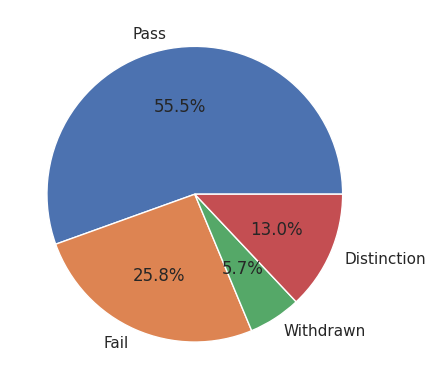

In [164]:
labels = df["final_result"].unique()
sns.set_theme(style = "ticks")
elist =[]
for i in range(len(labels)):
  elist.append((df["final_result"] == labels[i]).sum())

plt.pie(elist,labels = labels,autopct='%1.1f%%')
plt.savefig("new_pie.png")

In [165]:
resultord = ['Withdrawn','Fail','Pass','Distinction']
result_encoder = OrdinalEncoder(categories=[resultord])
df["final_result"] = result_encoder.fit_transform(df[["final_result"]])


In [166]:
enc = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

encoded = enc.fit_transform(
    df[['disability', 'gender']]
)

encoded_df = pd.DataFrame(
    encoded,
    columns=enc.get_feature_names_out(),
    index=df.index
)

df = pd.concat(
    [
        df.drop(columns=['disability', 'gender']),
        encoded_df
    ],
    axis=1
)


In [167]:
df

,id_student,code_module,scoreCA,num_of_prev_attempts,final_result,code_presentation,region,highest_education,imd_band,age_band,studied_credits,disability_N,disability_Y,gender_F,gender_M
0,11391,AAA,82.40,0,2.0,2013J,East Anglian Region,3.0,10.0,0.0,240,1.0,0.0,0.0,1.0
1,28400,AAA,65.40,0,2.0,2013J,Scotland,3.0,3.0,1.0,60,1.0,0.0,1.0,0.0
2,31604,AAA,76.30,0,2.0,2013J,South East Region,2.0,6.0,1.0,60,1.0,0.0,1.0,0.0
3,32885,AAA,55.00,0,2.0,2013J,West Midlands Region,1.0,6.0,2.0,60,1.0,0.0,1.0,0.0
4,38053,AAA,66.90,0,2.0,2013J,Wales,2.0,9.0,1.0,60,1.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20250,558764,FFF,82.75,0,2.0,2014J,East Midlands Region,1.0,2.0,2.0,60,1.0,0.0,0.0,1.0
20251,635985,FFF,9.00,0,1.0,2014J,North Western Region,2.0,9.0,2.0,120,1.0,0.0,0.0,1.0
20252,685367,FFF,19.25,0,1.0,2014J,Ireland,1.0,7.0,2.0,60,0.0,1.0,0.0,1.0
20253,491756,FFF,32.75,1,0.0,2013J,West Midlands Region,1.0,7.0,2.0,90,0.0,1.0,0.0,1.0


In [168]:
#combining with student activities dataset
df2 = pd.read_csv("/content/student_activities.csv")

#print(df.columns)
df
merged_df = pd.merge(
    df,
    df2,
    on=['id_student', 'code_module'],
    how='left'
)

In [169]:
merged_df
df=merged_df.drop(["scoreCA","num_of_prev_attempts","studied_credits","code_presentation","region","Unnamed: 0"],axis = 1)
df

,id_student,code_module,final_result,highest_education,imd_band,age_band,disability_N,disability_Y,gender_F,gender_M,...,ouelluminate,ouwiki,page,questionnaire,quiz,repeatactivity,resource,sharedsubpage,subpage,url
0,11391,AAA,2.0,3.0,10.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,13.0,0.0,32.0,5.0
1,28400,AAA,2.0,3.0,3.0,1.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,12.0,0.0,87.0,48.0
2,31604,AAA,2.0,2.0,6.0,1.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,19.0,0.0,144.0,90.0
3,32885,AAA,2.0,1.0,6.0,2.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,45.0,0.0,79.0,14.0
4,38053,AAA,2.0,2.0,9.0,1.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,11.0,0.0,91.0,45.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20250,558764,FFF,2.0,1.0,2.0,2.0,1.0,0.0,0.0,1.0,...,0.0,40.0,4.0,11.0,957.0,0.0,45.0,0.0,294.0,35.0
20251,635985,FFF,1.0,2.0,9.0,2.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,89.0,0.0,8.0,0.0,31.0,2.0
20252,685367,FFF,1.0,1.0,7.0,2.0,0.0,1.0,0.0,1.0,...,0.0,1.0,1.0,9.0,1.0,0.0,20.0,0.0,105.0,7.0
20253,491756,FFF,0.0,1.0,7.0,2.0,0.0,1.0,0.0,1.0,...,0.0,6.0,2.0,0.0,0.0,0.0,14.0,0.0,84.0,1.0
